In [1]:
# 功能：第 1/4 格，读取左右臂模拟数据，固定训练/测试划分，定义三种拟合共用的完整统计与 Notebook 内诊断绘图函数。
# 方法：uproot/awkward 转 NumPy float64；Left/Right 采用种子 42/43 分别划分 80%/20%；后续每种方法拟合完成即在 Notebook 内显示结果。
# 注意事项：输入顺序 ENaI、RDCX、RDCY，标签为顶点质子动能 ETrue；能量 MeV、坐标 mm；不新增物理筛选，不使用实验数据。
# SourceEntry 是预处理树行号，不是原始 EventID；每行一个筛选后事件，保持输入、真值和行号逐行对应。
# 本格不拟合、不预测；后面三格可在本格执行后分别运行。指标使用全部样本，不按残差图窗口筛选，不进行高斯拟合。
# 每种方法的训练/测试统计和逐事件测试结果仅保留在内存；六面板图只在 Notebook 显示，图框 4:3，图内仅保留坐标与刻度。
# 诊断图输出后集中打印左右臂完整 Train/Test 的 MAE、Bias、RMSE、RMS_68、W_68，统一六位小数及 MeV 单位；左侧标签不补空格，仅在冒号后按中英文显示宽度补齐并对齐数值，附理想高斯关系提示。
# 不创建诊断结果目录，不写 CSV、JSON、PDF、PNG；仅保留 PySR 必要搜索记录及供实验应用的 GPR 模型和预处理参数。
# 依赖 numpy、uproot、awkward、matplotlib；拟合格另需 sklearn，PySR 格另需 pysr、sympy 和 Julia。

from pathlib import Path
import awkward as ak
import numpy as np
import uproot

PROJECT_DIR = Path("/Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy")
INPUT_ROOT_DIR = PROJECT_DIR / "InputRootFiles"
INPUT_FILES = {
    "Left": INPUT_ROOT_DIR / "Processed_Left.root",
    "Right": INPUT_ROOT_DIR / "Processed_right.root",
}
TREE_NAME = "tree"
FEATURE_NAMES = ["ENaI", "RDCX", "RDCY"]
FEATURE_UNITS = ["MeV", "mm", "mm"]
TARGET_NAME = "ETrue"
INVALID_VALUE = -999.0
ARM_SEEDS = {"Left": 42, "Right": 43}
TRAIN_FRACTION = 0.80


def read_simulation(path):
    """一次读取同一批 entry 的三个标量输入和标签，保持逐行对应。"""
    path = Path(path).expanduser().resolve()
    if not path.is_file():
        raise FileNotFoundError(f"ROOT 文件不存在：{path}")
    names = FEATURE_NAMES + [TARGET_NAME]
    with uproot.open(path) as root_file:
        tree = root_file[TREE_NAME]
        missing = [name for name in names if name not in tree.keys()]
        if missing:
            raise ValueError(f"{path.name}/{TREE_NAME} 缺少分支：{missing}")
        arrays = tree.arrays(names, library="ak", how=dict)
        columns = [np.asarray(ak.to_numpy(arrays[name]), dtype=np.float64) for name in names]
    if any(column.ndim != 1 for column in columns):
        raise ValueError("需要每个事件一行的标量分支，不接受未预处理的多命中数组。")
    if len({len(column) for column in columns}) != 1:
        raise ValueError("输入与标签的行数不一致。")
    return np.column_stack(columns[:3]), columns[3]


datasets = {}
for arm, path in INPUT_FILES.items():
    X_all, y_all = read_simulation(path)
    # 与 EspriEnergy.ipynb 相同：坐标允许正负值，仅排除非有限值和 -999 哨兵值。
    input_ok = (np.isfinite(X_all).all(axis=1)
                & (X_all[:, 0] > 0.0)
                & (X_all != INVALID_VALUE).all(axis=1))
    target_ok = np.isfinite(y_all) & (y_all > 0.0)
    keep = input_ok & target_ok
    X, y = X_all[keep], y_all[keep]
    if len(X) < 5:
        raise ValueError(f"{arm} 有效事件数不足以划分训练/测试集。")
    datasets[arm] = {
        "X": X, "y": y,
        "source_rows": np.flatnonzero(keep).astype(np.int64),
        "input_path": path.resolve(),
        "original_entries": len(X_all),
        "rejected_entries": int((~keep).sum()),
    }
    print(f"{arm}: 原始 {len(X_all)}，输入无效 {(~input_ok).sum()}，"
          f"标签无效 {(~target_ok).sum()}，合计排除 {(~keep).sum()}，保留 {len(X)}")
    print(f"  X.shape={X.shape}, y.shape={y.shape}, dtype={X.dtype}")
    print("  feature minima:", dict(zip(FEATURE_NAMES, X.min(axis=0))))
    print("  feature maxima:", dict(zip(FEATURE_NAMES, X.max(axis=0))))
    print(f"  ETrue range: {y.min():.6g}–{y.max():.6g} MeV")


splits = {}
for arm, data in datasets.items():
    # 与 EspriEnergy.ipynb 使用完全相同的随机置换和训练/测试行号。
    order = np.random.default_rng(ARM_SEEDS[arm]).permutation(len(data["X"]))
    n_train = int(TRAIN_FRACTION * len(order))
    train_idx, test_idx = order[:n_train], order[n_train:]
    X_train, X_test = data["X"][train_idx], data["X"][test_idx]
    y_train, y_test = data["y"][train_idx], data["y"][test_idx]
    if len(y_test) < 2 or np.ptp(y_train) == 0.0 or np.ptp(y_test) == 0.0:
        raise ValueError(f"{arm}：R/R² 评估要求训练/测试标签非恒定，且测试集至少两个事件。")

    splits[arm] = {
        "train_idx": train_idx, "test_idx": test_idx,
        "train_source_rows": data["source_rows"][train_idx],
        "test_source_rows": data["source_rows"][test_idx],
        "X_train": X_train, "X_test": X_test,
        "y_train": y_train, "y_test": y_test,
    }
    print(f"{arm}: fixed train={len(train_idx)}, test={len(test_idx)}")


import matplotlib.pyplot as plt

RESIDUAL_HIST_MIN_MEV = -10.0
RESIDUAL_HIST_MAX_MEV = 10.0
RESIDUAL_HIST_BIN_WIDTH_MEV = 0.2
DIAGNOSTIC_FIGSIZE = (13.5, 7.3)


def regression_metrics(truth, prediction):
    """用全部有效样本计算 MeV 单位的统计量，常量真值时 R² 为 None。"""
    truth = np.asarray(truth, dtype=np.float64).reshape(-1)
    prediction = np.asarray(prediction, dtype=np.float64).reshape(-1)
    if truth.shape != prediction.shape:
        raise ValueError("真值与预测的事件数不一致。")
    if len(truth) == 0:
        raise ValueError("没有可用于计算误差的有效真值。")
    if not np.isfinite(truth).all() or not np.isfinite(prediction).all():
        raise ValueError("真值或预测存在非有限值，不能静默删除后再报告误差。")
    residual = prediction - truth
    mse = float(np.mean(residual**2))
    total = float(np.sum((truth - truth.mean())**2))
    q16, q50, q84 = np.quantile(residual, [0.16, 0.50, 0.84])
    core = residual[(residual >= q16) & (residual <= q84)]
    if core.size == 0:
        raise ValueError("Q16–Q84 区间内没有事件，无法计算 RMS_68。")
    r = (float(np.corrcoef(truth, prediction)[0, 1])
         if len(truth) > 1 and np.ptp(truth) > 0.0 and np.ptp(prediction) > 0.0 else None)
    return {
        "n": int(len(residual)), "mse_MeV2": mse,
        "rmse_MeV": float(np.sqrt(mse)), "mae_MeV": float(np.mean(np.abs(residual))),
        "r2": float(1.0 - np.sum(residual**2) / total) if total > 0.0 else None,
        "R": r,
        "bias_MeV": float(residual.mean()),
        "residual_std_MeV": float(residual.std(ddof=1)) if len(residual) > 1 else 0.0,
        "residual_q16_MeV": float(q16), "residual_median_MeV": float(q50),
        "residual_q84_MeV": float(q84),
        "truncated_rms68_MeV": float(np.sqrt(np.mean(core**2))),
        "central68_half_width_MeV": float((q84 - q16) / 2.0),
    }


def print_metric_rows(rows):
    """左侧标签保持自然间距，仅在冒号后补空格，使数值右对齐；中文占两列。"""
    import unicodedata

    def display_width(value):
        return sum(0 if unicodedata.combining(char) else
                   2 if unicodedata.east_asian_width(char) in ("W", "F") else 1
                   for char in value)

    labels = [f"{chinese} ({english}, {symbol}):"
              for chinese, english, symbol, _, _ in rows]
    label_width = max(display_width(label) for label in labels)
    value_width = max(14, max(display_width(row[3]) for row in rows))
    for label, (_, _, _, value, unit) in zip(labels, rows):
        # 所有用于对齐的空格均位于冒号之后，不在名称或括号内补空格。
        padding = label_width - display_width(label) + 1 + value_width - display_width(value)
        print(f"{label}{' ' * padding}{value} {unit}".rstrip(), flush=True)


def print_regression_metrics(method, arm, subset, metrics):
    """按 skill 固定顺序打印完整数据划分的五项误差，单位均为 MeV。"""
    print(f"\n{method} {arm} {subset}（完整评估样本数：{metrics['n']}）", flush=True)
    labels = [
        ("平均绝对误差", "Mean Absolute Error", "MAE", "mae_MeV"),
        ("平均偏差", "Mean Bias", "Bias", "bias_MeV"),
        ("均方根误差", "Root Mean Square Error", "RMSE", "rmse_MeV"),
        ("截尾均方根", "Truncated RMS", "RMS_68", "truncated_rms68_MeV"),
        ("中心68%半宽", "Central 68% Half Width", "W_68", "central68_half_width_MeV"),
    ]
    print_metric_rows([
        (chinese, english, symbol, f"{metrics[key]:.6f}", "MeV")
        for chinese, english, symbol, key in labels
    ])


def finish_diagnostic_figure(fig, axes):
    """统一图框、科学计数法和首尾刻度文字，不写图像文件。"""
    for ax in axes.flat:
        ax.set_box_aspect(3.0 / 4.0)
        ax.tick_params(axis="both", which="both", direction="in", top=True, right=True)
        ax.grid(False)
    fig.canvas.draw()
    for ax in axes.flat:
        low, high = sorted(ax.get_ylim())
        ticks = ax.get_yticks()
        visible = np.abs(ticks[(ticks >= low) & (ticks <= high) & (ticks != 0.0)])
        if visible.size and np.any((visible > 1000.0) | (visible < 0.001)):
            exponent = int(np.floor(np.log10(visible.max())))
            ax.ticklabel_format(axis="y", style="sci", scilimits=(exponent, exponent),
                                useMathText=True, useOffset=False)
    fig.canvas.draw()
    for ax in axes.flat:
        low, high = sorted(ax.get_xlim())
        ticks = [tick for tick in ax.xaxis.get_major_ticks() if low <= tick.get_loc() <= high]
        if len(ticks) > 1:
            ticks[0].label1.set_visible(False)
            ticks[-1].label1.set_visible(False)


def plot_diagnostics(arm, X, truth, prediction, sample_label):
    """六面板中的宽度均为样本统计量；不做高斯拟合，不截除尾部事件。"""
    X = np.asarray(X, dtype=np.float64)
    truth = np.asarray(truth, dtype=np.float64).reshape(-1)
    prediction = np.asarray(prediction, dtype=np.float64).reshape(-1)
    stats = regression_metrics(truth, prediction)
    if X.shape != (len(truth), 3):
        raise ValueError("诊断输入必须与真值逐行对应，且顺序为 ENaI、RDCX、RDCY。")
    residual = prediction - truth
    fig, axes = plt.subplots(2, 3, figsize=DIAGNOSTIC_FIGSIZE, layout="constrained")
    ax = axes[0, 0]
    ax.scatter(truth, prediction, s=7, color="#000000", alpha=0.35, linewidths=0)
    bounds = [min(truth.min(), prediction.min()), max(truth.max(), prediction.max())]
    ax.plot(bounds, bounds, color="black", linestyle="--", linewidth=1)
    ax.set_xlabel("True proton energy (MeV)", loc="center")
    ax.set_ylabel("Predicted proton energy (MeV)", loc="center")

    ax = axes[0, 1]
    bin_count = int(round((RESIDUAL_HIST_MAX_MEV - RESIDUAL_HIST_MIN_MEV)
                          / RESIDUAL_HIST_BIN_WIDTH_MEV))
    histogram_edges = np.linspace(RESIDUAL_HIST_MIN_MEV, RESIDUAL_HIST_MAX_MEV, bin_count + 1)
    counts, edges = np.histogram(residual, bins=histogram_edges)
    ax.stairs(counts, edges, color="blue", linewidth=1.2)
    ax.set_xlim(RESIDUAL_HIST_MIN_MEV, RESIDUAL_HIST_MAX_MEV)
    ax.set_ylim(0.0, max(1.0, 1.18 * counts.max()))
    ax.set_xlabel("Predicted - true energy (MeV)", loc="center")
    ax.set_ylabel(f"Counts / {edges[1] - edges[0]:.3g} MeV", loc="center")
    ax.axvline(0.0, color="black", linestyle="--", linewidth=1)
    print(f"{arm} {sample_label}: residual histogram below range="
          f"{(residual < RESIDUAL_HIST_MIN_MEV).sum()}, "
          f"above range={(residual > RESIDUAL_HIST_MAX_MEV).sum()}; "
          f"metrics use all {stats['n']} events", flush=True)

    xs = [truth, X[:, 0], X[:, 1], X[:, 2]]
    labels = ["True proton energy (MeV)", "NaI readout energy (MeV)", "RDCX (mm)", "RDCY (mm)"]
    residual_limit = max(1e-6, 1.08 * np.max(np.abs(residual)))
    for ax, values, label in zip([axes[0, 2], *axes[1]], xs, labels):
        ax.scatter(values, residual, s=7, color="#000000", alpha=0.35, linewidths=0)
        ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
        ax.set_xlabel(label, loc="center")
        ax.set_ylabel("Predicted - true energy (MeV)", loc="center")
        ax.set_ylim(-residual_limit, residual_limit)
    finish_diagnostic_figure(fig, axes)
    plt.show()
    plt.close(fig)
    return fig



all_metrics, test_results = {}, {}


def display_model_outputs(method, cached_results):
    """使用当前方法的内存结果显示诊断图和统计，不重新拟合、预测或写文件。"""
    all_metrics[method], test_results[method] = {}, {}
    for arm in ("Left", "Right"):
        split = splits[arm]
        all_metrics[method][arm] = {}
        for subset in ("train", "test"):
            prediction = np.asarray(cached_results[arm][subset.capitalize()]["prediction"],
                                    dtype=np.float64).reshape(-1)
            truth = np.asarray(split[f"y_{subset}"], dtype=np.float64).reshape(-1)
            all_metrics[method][arm][subset] = regression_metrics(truth, prediction)
            if subset == "test":
                test_results[method][arm] = {
                    "source_rows": split["test_source_rows"].copy(),
                    "X": split["X_test"], "truth": truth, "prediction": prediction,
                    "residual": prediction - truth,
                }
    for arm, result in test_results[method].items():
        plot_diagnostics(arm, result["X"], result["truth"], result["prediction"],
                         f"{method}, internal test")
    # 两臂测试诊断图全部输出后，再集中打印两臂完整 Train/Test 的统计量。
    for arm in ("Left", "Right"):
        for subset in ("Train", "Test"):
            print_regression_metrics(method, arm, subset,
                                     all_metrics[method][arm][subset.lower()])
    print("\n零偏差理想高斯分布的理论关系：", flush=True)
    print_metric_rows([
        ("标准差", "Standard Deviation", "σ", "σ", ""),
        ("均方根误差", "Root Mean Square Error", "RMSE", "σ", "（Bias = 0）"),
        ("截尾均方根", "Truncated RMS", "RMS_68", "≈ 0.54σ", ""),
        ("中心68%半宽", "Central 68% Half Width", "W_68", "≈ 0.994σ", ""),
    ])
    print("以上关系仅适用于相应高斯假设；不能仅凭 RMS_68/W_68 接近 0.54 判定残差服从高斯分布。", flush=True)


Left: 原始 24006，输入无效 0，标签无效 0，合计排除 0，保留 24006
  X.shape=(24006, 3), y.shape=(24006,), dtype=float64
  feature minima: {'ENaI': np.float64(0.2078763012513422), 'RDCX': np.float64(112.06673818573219), 'RDCY': np.float64(18.522068663701816)}
  feature maxima: {'ENaI': np.float64(125.91301180247619), 'RDCX': np.float64(399.3273479131202), 'RDCY': np.float64(427.92354384297494)}
  ETrue range: 18.5195–179.996 MeV
Right: 原始 24149，输入无效 0，标签无效 0，合计排除 0，保留 24149
  X.shape=(24149, 3), y.shape=(24149,), dtype=float64
  feature minima: {'ENaI': np.float64(0.15498845045936438), 'RDCX': np.float64(48.45831757412378), 'RDCY': np.float64(24.51877856102081)}
  feature maxima: {'ENaI': np.float64(137.54049436590878), 'RDCX': np.float64(331.00826472962615), 'RDCY': np.float64(424.37408075696976)}
  ETrue range: 22.7589–179.996 MeV
Left: fixed train=19204, test=4802
Right: fixed train=19319, test=4830


线性回归


Left: train=19204, test=4802
ETrue_fit [MeV] = 117.0024707 +0.8143207158*ENaI -0.2943078877*RDCX +0.0009866853653*RDCY
  ENaI 系数单位：MeV/MeV；RDCX、RDCY 系数单位：MeV/mm；截距单位：MeV。

Right: train=19319, test=4830
ETrue_fit [MeV] = -14.51857905 +0.8147053755*ENaI +0.2937200156*RDCX -0.0003813714561*RDCY
  ENaI 系数单位：MeV/MeV；RDCX、RDCY 系数单位：MeV/mm；截距单位：MeV。
Left Linear, internal test: residual histogram below range=801, above range=834; metrics use all 4802 events


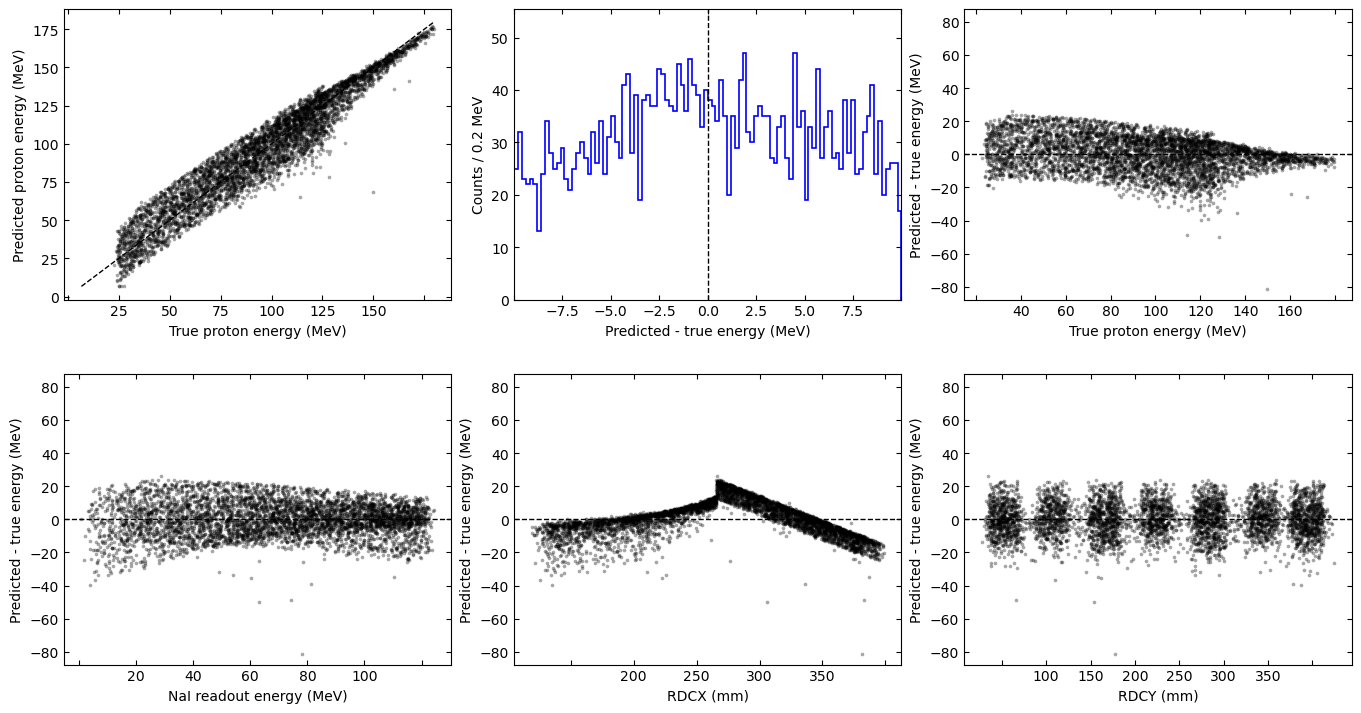

Right Linear, internal test: residual histogram below range=807, above range=822; metrics use all 4830 events


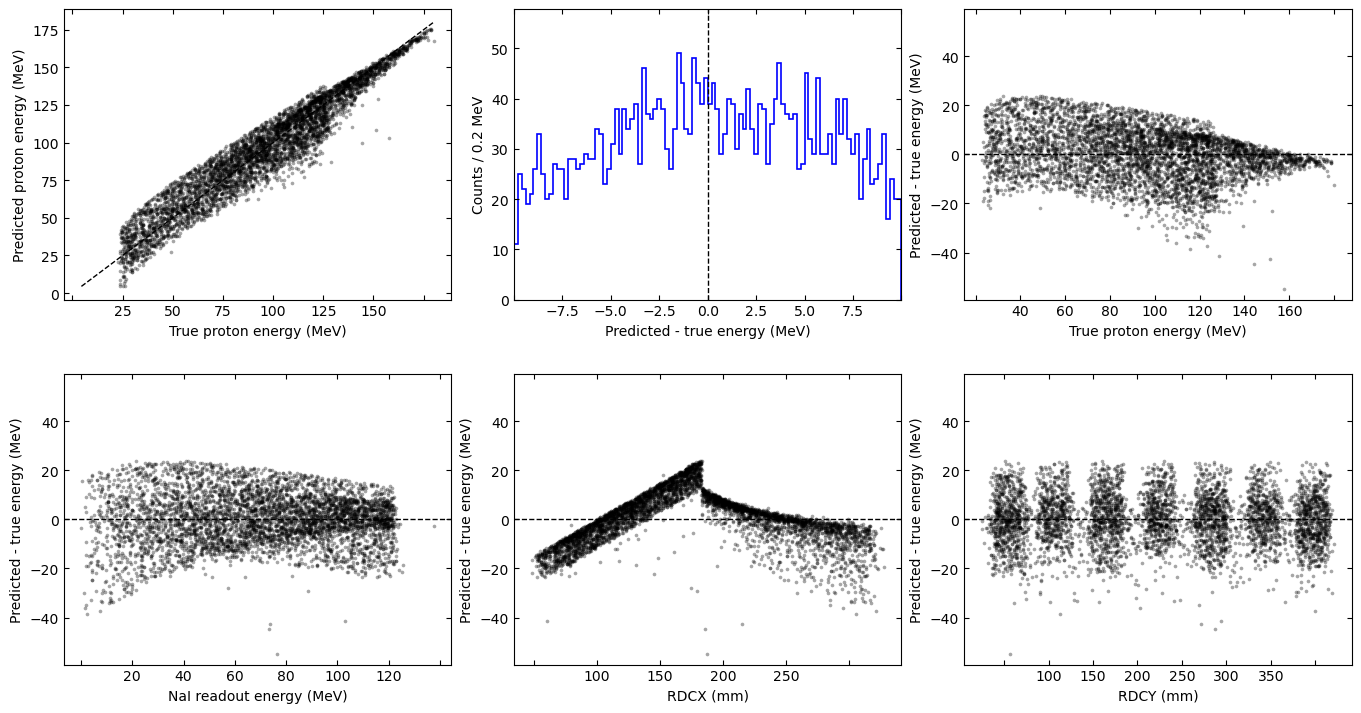


Linear Left Train（完整评估样本数：19204）
平均绝对误差 (Mean Absolute Error, MAE):          8.337870 MeV
平均偏差 (Mean Bias, Bias):                       0.000000 MeV
均方根误差 (Root Mean Square Error, RMSE):       10.396339 MeV
截尾均方根 (Truncated RMS, RMS_68):               5.682961 MeV
中心68%半宽 (Central 68% Half Width, W_68):      10.556586 MeV

Linear Left Test（完整评估样本数：4802）
平均绝对误差 (Mean Absolute Error, MAE):          8.288604 MeV
平均偏差 (Mean Bias, Bias):                       0.056809 MeV
均方根误差 (Root Mean Square Error, RMSE):       10.388732 MeV
截尾均方根 (Truncated RMS, RMS_68):               5.626021 MeV
中心68%半宽 (Central 68% Half Width, W_68):      10.463748 MeV

Linear Right Train（完整评估样本数：19319）
平均绝对误差 (Mean Absolute Error, MAE):          8.228057 MeV
平均偏差 (Mean Bias, Bias):                      -0.000000 MeV
均方根误差 (Root Mean Square Error, RMSE):       10.308303 MeV
截尾均方根 (Truncated RMS, RMS_68):               5.531156 MeV
中心68%半宽 (Central 68% Half Width, W_68):      10.348783 MeV

Linear Right Test（完整评估样本数

In [2]:
# 功能：第 2/4 格，分别线性拟合左右臂 ETrue=b+a*ENaI+c*RDCX+d*RDCY，在 Notebook 内显示统计指标和诊断图。
# 方法：复用第一格的固定划分，sklearn LinearRegression 拟合训练集；内存保留 R、R² 等完整统计；诊断图后统一打印完整 Train/Test 的五项 MeV 误差。
# 注意事项：先运行第一格；仅训练集用于拟合，原单位系数为 MeV/MeV 或 MeV/mm；R/R² 不能单独证明线性或非线性。
# 左右臂六面板仅在 Notebook 显示；完整统计和逐事件结果保留在内存，不写结果文件。
# 残差直方图显示 −10～10 MeV、0.2 MeV/bin，全部指标使用所有事件。

from sklearn.linear_model import LinearRegression

# 示例筛查阈值，并非统计显著性标准或物理精度要求；不据此选择、调整模型。
R_SCREEN = 0.99




models, fit_results = {}, {}
for arm, split in splits.items():
    X_train, X_test = split["X_train"], split["X_test"]
    y_train, y_test = split["y_train"], split["y_test"]
    train_idx, test_idx = split["train_idx"], split["test_idx"]
    model = LinearRegression(fit_intercept=True)
    model.fit(X_train, y_train)
    models[arm] = model
    fit_results[arm] = {}
    print(f"\n{arm}: train={len(train_idx)}, test={len(test_idx)}")
    formula = f"ETrue_fit [MeV] = {model.intercept_:.10g}"
    for name, coefficient in zip(FEATURE_NAMES, model.coef_):
        formula += f" {coefficient:+.10g}*{name}"
    print(formula)
    print("  ENaI 系数单位：MeV/MeV；RDCX、RDCY 系数单位：MeV/mm；截距单位：MeV。")
    if model.rank_ < len(FEATURE_NAMES):
        print("  提示：训练输入秩不足，部分系数不能被独立确定。")

    for subset, X_part, y_part in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        prediction = model.predict(X_part)
        metrics = regression_metrics(y_part, prediction)
        fit_results[arm][subset] = {
            "prediction": prediction, "residual": prediction - y_part, "metrics": metrics,
        }

display_model_outputs("Linear", fit_results)


符号回归

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython
PySR 搜索输出目录： /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/TradFit/output_20261028_105319

Left PySR: 拟合完整训练集 19204 条，测试 4802 条


Compiling Julia backend...
[ Info: Started!



Expressions evaluated per second: 8.550e+03
Progress: 541 / 800 total iterations (67.625%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           1.000e+00  0.000e+00  y = 0
3           3.517e-01  5.224e-01  y = zENaI - zRDCX
5           8.733e-02  6.966e-01  y = (zENaI - zRDCX) / 1.5417
7           8.049e-02  4.078e-02  y = (zENaI - (zRDCX * 0.81954)) * 0.72153
9           8.038e-02  6.547e-04  y = (zRDCX / 7.9283) + ((zENaI - zRDCX) / 1.4038)
10          6.602e-02  1.968e-01  y = ((square(zRDCX / 2.4345) + zENaI) - zRDCX) / 1.5616
12          2.962e-02  4.007e-01  y = (zENaI + (square((zRDCX + -1.1549) * 0.57284) + -0.769...
                                      33)) / 1.4087
14          2.658e-02  5.419e-02  y = square((zRDCX * 0.42551) + (-0.66868 + (zENaI * 0.1969...
               

[ Info: Final population:
[ Info: Results saved to:
[ Info: Started!


  - /Users/yemingxin/ROOT_Exercise/MachineLearning/EspriEnergy/TradFit/output_20261028_105319/Left/hall_of_fame.csv

Expressions evaluated per second: 8.600e+03
Progress: 569 / 800 total iterations (71.125%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           7.106e-01  0.000e+00  y = zRDCX
3           3.585e-01  3.420e-01  y = zRDCX + zENaI
5           8.762e-02  7.045e-01  y = (zRDCX + zENaI) / 1.5428
7           7.973e-02  4.717e-02  y = (zENaI + (zRDCX * 0.82527)) * 0.70728
9           7.970e-02  1.600e-04  y = ((zRDCX * -0.1817) + (zENaI + zRDCX)) / 1.409
10          6.719e-02  1.709e-01  y = ((zRDCX + (square(zRDCX) * 0.1619)) + zENaI) / 1.5688
12          3.054e-02  3.942e-01  y = ((zENaI + -0.76142) / 1.4064) + square((zRDCX * 0.4900...
                                      5) 

[ Info: Final population:
[ Info: Results saved to:


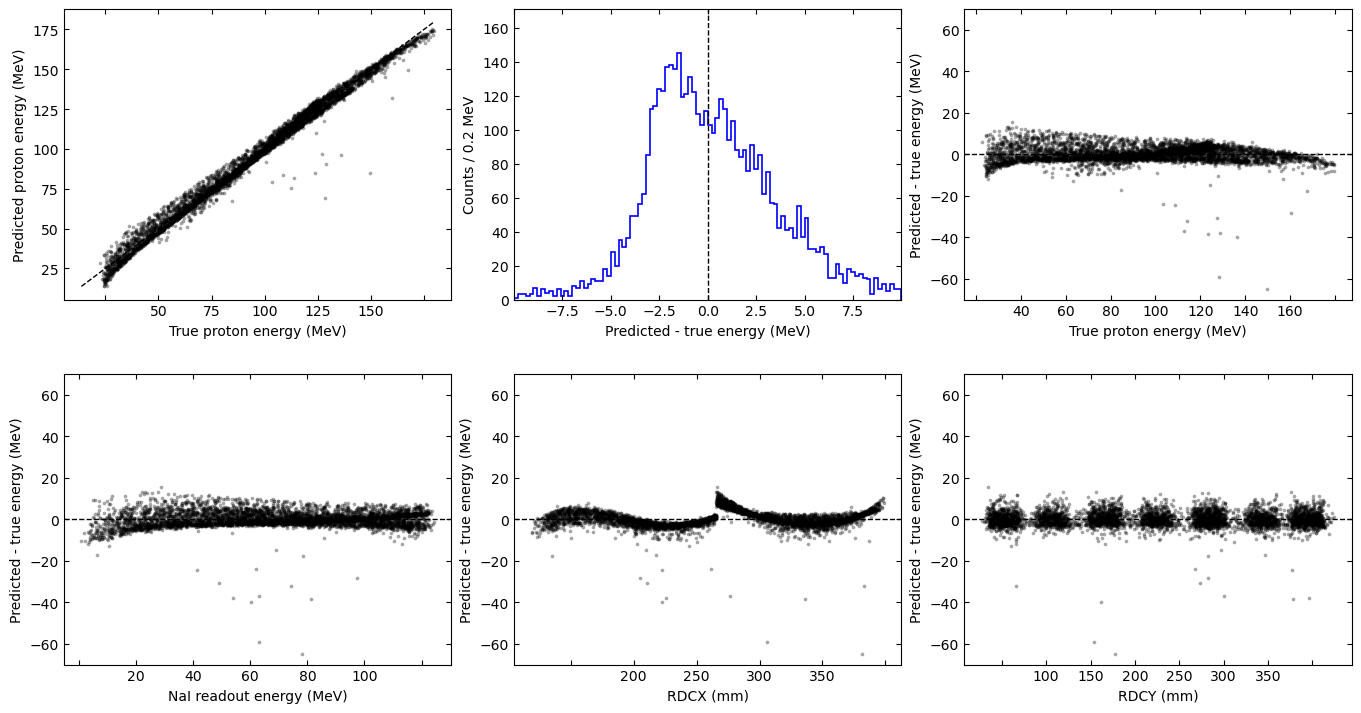

Right PySR, internal test: residual histogram below range=93, above range=221; metrics use all 4830 events


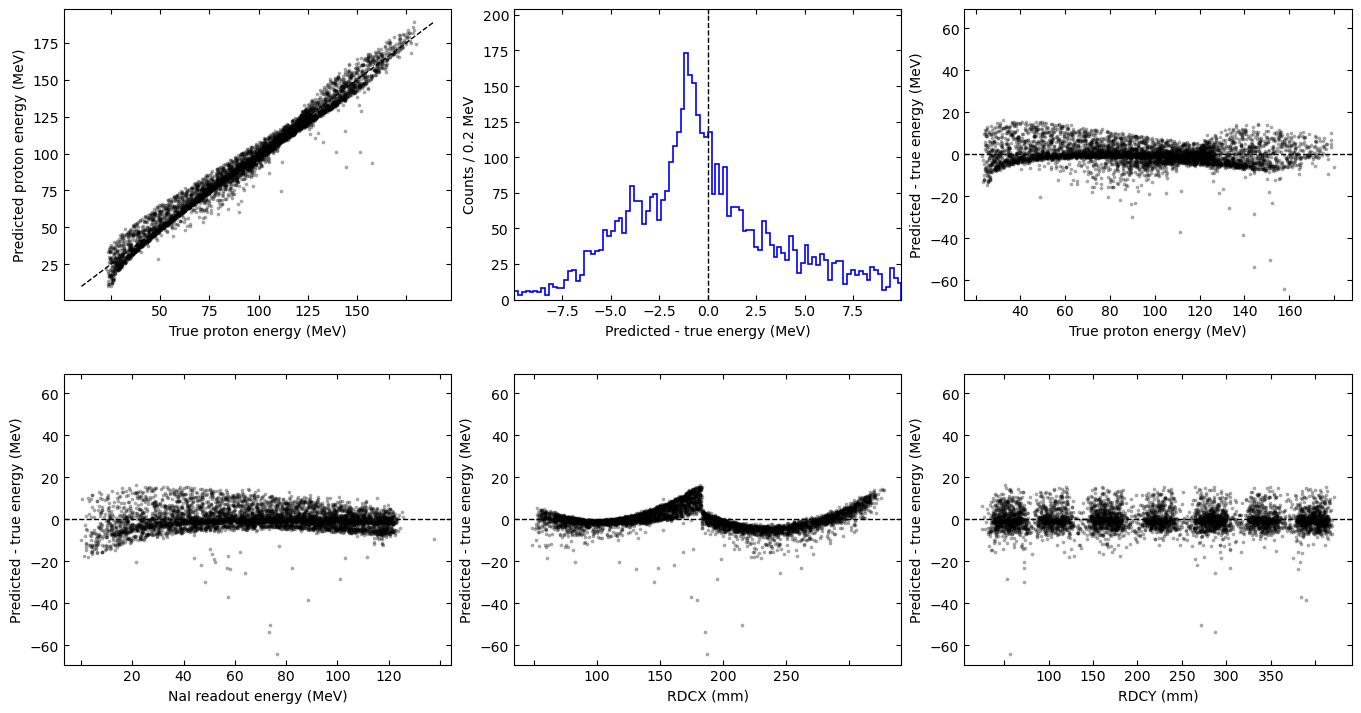


PySR Left Train（完整评估样本数：19204）
平均绝对误差 (Mean Absolute Error, MAE):          2.692810 MeV
平均偏差 (Mean Bias, Bias):                       0.193247 MeV
均方根误差 (Root Mean Square Error, RMSE):        3.801198 MeV
截尾均方根 (Truncated RMS, RMS_68):               1.703631 MeV
中心68%半宽 (Central 68% Half Width, W_68):       3.088610 MeV

PySR Left Test（完整评估样本数：4802）
平均绝对误差 (Mean Absolute Error, MAE):          2.736752 MeV
平均偏差 (Mean Bias, Bias):                       0.175046 MeV
均方根误差 (Root Mean Square Error, RMSE):        3.929265 MeV
截尾均方根 (Truncated RMS, RMS_68):               1.740453 MeV
中心68%半宽 (Central 68% Half Width, W_68):       3.144505 MeV

PySR Right Train（完整评估样本数：19319）
平均绝对误差 (Mean Absolute Error, MAE):          3.657177 MeV
平均偏差 (Mean Bias, Bias):                      -0.033318 MeV
均方根误差 (Root Mean Square Error, RMSE):        5.123546 MeV
截尾均方根 (Truncated RMS, RMS_68):               2.151197 MeV
中心68%半宽 (Central 68% Half Width, W_68):       4.320647 MeV

PySR Right Test（完整评估样本数：4830）
平

In [3]:
# 功能：第 3/4 格，使用 PySR 独立搜索左右臂的显式经验公式，在 Notebook 内显示统计指标和六面板图。
# 方法：复用第一格的完整训练/测试划分；训练集标准化输入与标签，搜索 +、-、*、/、square；训练损失和复杂度用于选式。
# 注意事项：先运行第一格；不使用测试集选式；公式代回 ENaI、RDCX、RDCY 的 MeV/mm 原单位，不据此宣称物理定律，外推可能遇到奇点。
# nn 兼容组合为 pysr 1.5.10、juliacall 0.9.26、sympy 1.13.1；复用当前 Python 的 Julia 项目和运行时，尊重显式环境变量。
# 固定种子、serial、float64；首次导入可能初始化 Julia 依赖，本格不执行 pip 安装；搜索记录仍保存在 TradFit 时间戳目录。
# 诊断图后打印完整 Train/Test 的五项 MeV 误差；完整统计和预测仅保留在内存；按用户要求保留 TradFit 中 PySR 必需的搜索记录和检查点。

from datetime import datetime
from importlib.util import find_spec

SR_ITERATIONS = 100
SR_POPULATIONS = 8
SR_POPULATION_SIZE = 50
SR_CYCLES = 100
SR_MAXSIZE = 25
SR_BATCH_SIZE = 512

if "splits" not in globals() or "regression_metrics" not in globals():
    raise RuntimeError("请先运行第一个单元格，建立左右臂数据、固定划分及公共输出函数。")
if find_spec("pysr") is None:
    raise ModuleNotFoundError(
        "当前 Notebook 内核未安装 pysr。请先在该内核环境安装 pysr、sympy 并准备 Julia，再运行本格。"
    )

import os
import sys

# 固定 Julia 项目位置，避免终端与 Notebook 因 CONDA_PREFIX 不同而重复初始化。
os.environ.setdefault("PYTHON_JULIAPKG_PROJECT", str(Path(sys.prefix) / "julia_env"))
julia_executable = Path(sys.prefix) / "julia_env" / "pyjuliapkg" / "install" / "bin" / "julia"
if julia_executable.is_file():
    os.environ.setdefault("PYTHON_JULIAPKG_EXE", str(julia_executable))

from pysr import PySRRegressor
from sklearn.preprocessing import StandardScaler
import sympy as sp

SR_OUTPUT_DIR = PROJECT_DIR / "TradFit" / datetime.now().strftime("output_%Y%m%d_%H%M%S")
SR_OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
print("PySR 搜索输出目录：", SR_OUTPUT_DIR, flush=True)

pysr_models, pysr_results = {}, {}
for arm, split in splits.items():
    X_train, y_train = split["X_train"], split["y_train"]
    scaler = StandardScaler().fit(X_train)
    y_mean, y_scale = float(y_train.mean()), float(y_train.std())
    if y_scale == 0.0:
        raise ValueError(f"{arm} 训练标签为常量，无法标准化。")
    z_names = [f"z{name}" for name in FEATURE_NAMES]
    sr_model = PySRRegressor(
        niterations=SR_ITERATIONS,
        populations=SR_POPULATIONS,
        population_size=SR_POPULATION_SIZE,
        ncycles_per_iteration=SR_CYCLES,
        binary_operators=["+", "-", "*", "/"],
        unary_operators=["square"],
        maxsize=SR_MAXSIZE,
        model_selection="best",
        batching=True, batch_size=min(SR_BATCH_SIZE, len(y_train)),
        precision=64,
        parallelism="serial", deterministic=True, random_state=ARM_SEEDS[arm],
        output_directory=str(SR_OUTPUT_DIR), run_id=arm,
        progress=False,
    )
    print(f"\n{arm} PySR: 拟合完整训练集 {len(y_train)} 条，测试 {len(split['y_test'])} 条", flush=True)
    sr_model.fit(
        scaler.transform(X_train), (y_train - y_mean) / y_scale,
        variable_names=z_names,
    )
    # sympy() 与默认 predict() 均使用 model_selection='best' 选出的同一表达式。
    normalized_expression = sr_model.sympy()
    substitutions = {
        sp.Symbol(zname): (sp.Symbol(name) - float(mean)) / float(scale)
        for zname, name, mean, scale in zip(z_names, FEATURE_NAMES, scaler.mean_, scaler.scale_)
    }
    expression = y_mean + y_scale * normalized_expression.subs(substitutions)
    pysr_models[arm] = {
        "model": sr_model, "scaler": scaler, "y_mean": y_mean, "y_scale": y_scale,
        "expression": expression, "source_rows": split["train_source_rows"].copy(),
    }
    pysr_results[arm] = {}
    print("  候选公式（loss 为标准化 ETrue 上的训练均方误差）：")
    print(sr_model.equations_[["complexity", "loss", "equation"]].to_string(index=False))
    print(f"  原单位公式：ETrue_fit [MeV] = {expression}")
    for subset in ("Train", "Test"):
        X_part, y_part = split[f"X_{subset.lower()}"], split[f"y_{subset.lower()}"]
        prediction = y_mean + y_scale * np.asarray(
            sr_model.predict(scaler.transform(X_part)), dtype=np.float64,
        ).reshape(-1)
        if not np.isfinite(prediction).all():
            raise ValueError(f"{arm} PySR {subset} 预测包含非有限值，请检查表达式定义域。")
        metrics = regression_metrics(y_part, prediction)
        pysr_results[arm][subset] = {
            "prediction": prediction, "residual": prediction - y_part, "metrics": metrics,
        }

display_model_outputs("PySR", pysr_results)


| 统计指标 | 理想高斯分布下的值 |
|---|---|
| 标准差（Standard Deviation） | $\sigma$ |
| 均方根误差（RMSE，Bias = 0） | $\sigma$ |
| 截尾均方根（Truncated RMS 68%） | $\approx 0.54\sigma$ |
| 中心 68% 半宽（Central 68% Half Width） | $\approx 0.994\sigma$ |

高斯过程回归

每臂按当前配置从模拟训练集抽取最多 7500 条拟合；测试集不参与拟合。
仅将两臂完整 GPR、已拟合 StandardScaler、输入/目标定义及拟合元数据保存至 `GPR/gpr_models.pkl`。
`ForExperiment.ipynb` 最后两个代码单元格直接加载此文件，可使用独立内核；不在实验数据上重新训练或归一化。
不导出诊断 CSV、JSON、PDF 或 PNG；运行本格会更新同名 GPR 模型文件。



Left GPR: 拟合 7500/19204 条训练事件，测试 4802 条

Left GPR 优化后的核函数（LaTeX 渲染）：


<IPython.core.display.Math object>

<IPython.core.display.Math object>

输入特征与优化后的相关长度（标准化坐标）：
  z_1: ENaI [MeV], length_scale = 3.07216
  z_2: RDCX [mm], length_scale = 0.146464
  z_3: RDCY [mm], length_scale = 962.98
  Signal variance (normalized y): 1.57538
  White noise variance (normalized y): 0.00246972
  WhiteKernel 等效噪声标准差: 1.834018 MeV

Right GPR: 拟合 7500/19319 条训练事件，测试 4830 条


/opt/anaconda3/envs/nn/lib/python3.11/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(



Right GPR 优化后的核函数（LaTeX 渲染）：


<IPython.core.display.Math object>

<IPython.core.display.Math object>

输入特征与优化后的相关长度（标准化坐标）：
  z_1: ENaI [MeV], length_scale = 2.76984
  z_2: RDCX [mm], length_scale = 0.164458
  z_3: RDCY [mm], length_scale = 1000
  Signal variance (normalized y): 1.3478
  White noise variance (normalized y): 0.0022538
  WhiteKernel 等效噪声标准差: 1.726487 MeV
Left GPR, internal test: residual histogram below range=14, above range=0; metrics use all 4802 events


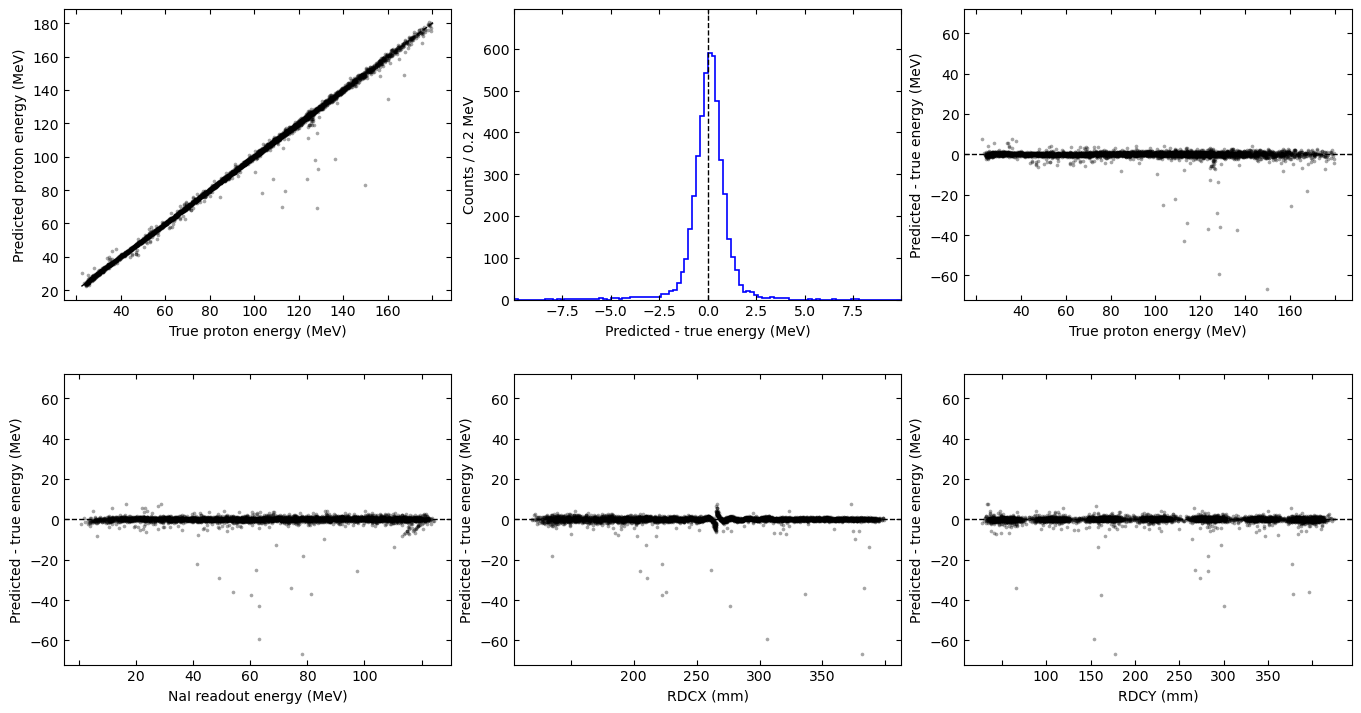

Right GPR, internal test: residual histogram below range=22, above range=0; metrics use all 4830 events


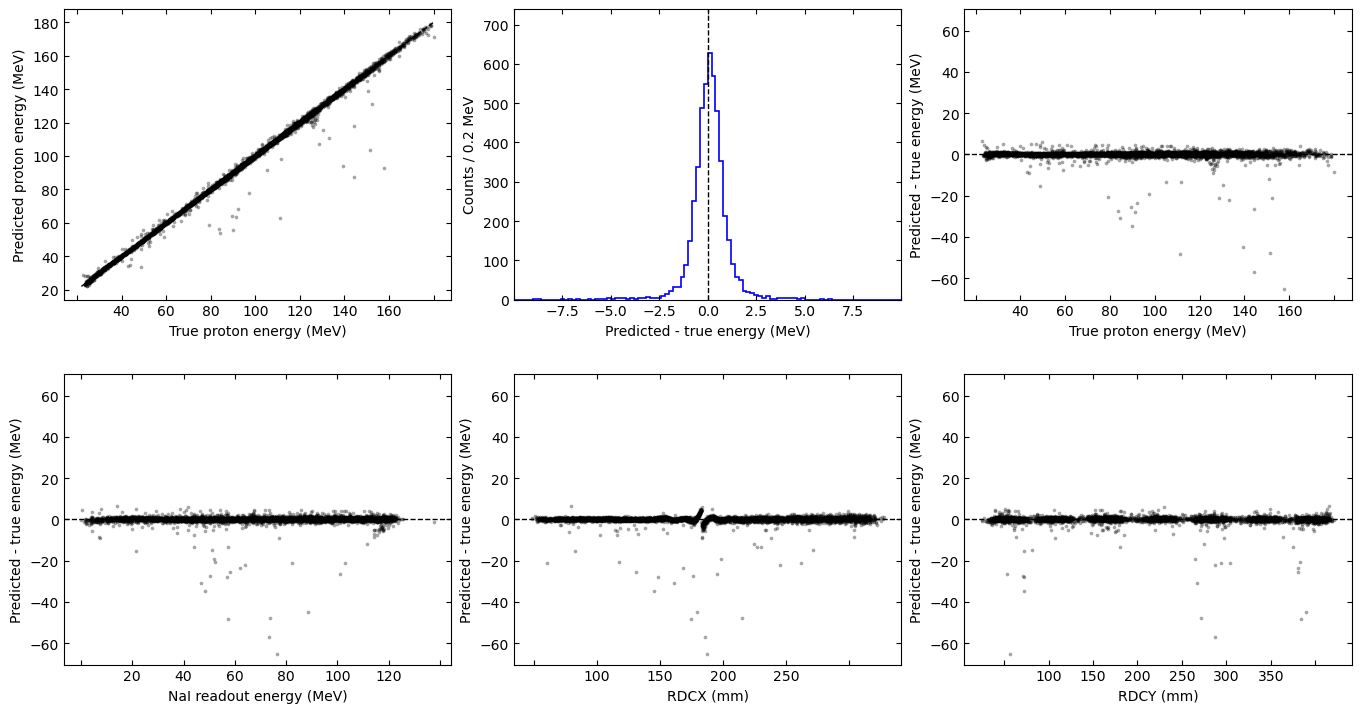


GPR Left Train（完整评估样本数：19204）
平均绝对误差 (Mean Absolute Error, MAE):          0.702686 MeV
平均偏差 (Mean Bias, Bias):                      -0.019611 MeV
均方根误差 (Root Mean Square Error, RMSE):        1.943279 MeV
截尾均方根 (Truncated RMS, RMS_68):               0.360952 MeV
中心68%半宽 (Central 68% Half Width, W_68):       0.665497 MeV

GPR Left Test（完整评估样本数：4802）
平均绝对误差 (Mean Absolute Error, MAE):          0.735547 MeV
平均偏差 (Mean Bias, Bias):                      -0.040868 MeV
均方根误差 (Root Mean Square Error, RMSE):        2.190281 MeV
截尾均方根 (Truncated RMS, RMS_68):               0.368563 MeV
中心68%半宽 (Central 68% Half Width, W_68):       0.689233 MeV

GPR Right Train（完整评估样本数：19319）
平均绝对误差 (Mean Absolute Error, MAE):          0.715229 MeV
平均偏差 (Mean Bias, Bias):                      -0.011637 MeV
均方根误差 (Root Mean Square Error, RMSE):        2.014528 MeV
截尾均方根 (Truncated RMS, RMS_68):               0.353052 MeV
中心68%半宽 (Central 68% Half Width, W_68):       0.650534 MeV

GPR Right Test（完整评估样本数：4830）
平均绝对误

In [6]:
# 功能：第 4/4 格，使用 GaussianProcessRegressor 独立拟合左右臂，显示完整统计、六面板图、LaTeX 核函数及预测不确定度。
# 方法：复用第一格划分；每臂固定种子抽取最多 7500 条，使用 StandardScaler、各向异性 RBF + WhiteKernel。
# 不确定度：prediction_std 为包含 WhiteKernel 的预测标准差；latent_std 为扣除白噪声贡献后的潜在函数标准差，单位 MeV。
# 统计：68.3%/95% coverage 分别统计 |预测-真值| <= 1σ 和 <= 1.96σ 的事件比例。
# 模型：保留原有 gpr_models 数据结构和 gpr_models.pkl 保存方式，实验 Notebook 无需重新训练。

import pickle
import numpy as np
import sklearn
from IPython.display import display, Math
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel
from sklearn.preprocessing import StandardScaler

GP_MAX_TRAIN = 7500
GP_PREDICT_BATCH = 512
GP_RESTARTS = 0
GP_PRINT_TEST_EVENTS = 10  # 每臂打印前 10 个测试事件；设为 0 则不打印逐事件结果

if "splits" not in globals() or "regression_metrics" not in globals() or "display_model_outputs" not in globals():
    raise RuntimeError("请先运行第一个单元格，建立左右臂数据、固定划分及公共输出函数。")


def predict_gp(model, scaler, X, return_std=False):
    """分批预测 GPR；return_std=True 时同时返回预测均值和标准差，单位 MeV。"""
    if len(X) == 0:
        empty = np.empty(0, dtype=np.float64)
        return (empty, empty.copy()) if return_std else empty

    outputs = [
        model.predict(scaler.transform(X[start:start + GP_PREDICT_BATCH]), return_std=return_std)
        for start in range(0, len(X), GP_PREDICT_BATCH)
    ]

    if return_std:
        return np.concatenate([result[0] for result in outputs]), np.concatenate([result[1] for result in outputs])
    return np.concatenate(outputs)


def display_gp_kernel(arm, model, feature_names, feature_units):
    """将优化后的 ConstantKernel * RBF + WhiteKernel 渲染为完整 LaTeX 数学公式。"""
    fitted_kernel = model.kernel_
    amplitude = float(fitted_kernel.k1.k1.constant_value)
    length_scales = np.atleast_1d(fitted_kernel.k1.k2.length_scale)
    noise_level = float(fitted_kernel.k2.noise_level)

    terms = [rf"\frac{{(z_{{{i+1}}}-z'_{{{i+1}}})^2}}{{({ell:.5g})^2}}" for i, ell in enumerate(length_scales)]
    formula = rf"k_{{\mathrm{{{arm}}}}}(\mathbf{{z}},\mathbf{{z}}')={amplitude:.6g}\exp\left[-\frac{{1}}{{2}}\left({'+'.join(terms)}\right)\right]+{noise_level:.6g}\,\delta_{{ij}}"

    print(f"\n{arm} GPR 优化后的核函数（LaTeX 渲染）：")
    display(Math(formula))
    display(Math(r"z_j=\frac{x_j-\mu_j}{s_j},\qquad \delta_{ij}=\begin{cases}1,&i=j\\0,&i\neq j\end{cases}"))

    print("输入特征与优化后的相关长度（标准化坐标）：")
    for i, (name, unit, ell) in enumerate(zip(feature_names, feature_units, length_scales), 1):
        print(f"  z_{i}: {name} [{unit}], length_scale = {ell:.6g}")

    print(f"  Signal variance (normalized y): {amplitude:.6g}")
    print(f"  White noise variance (normalized y): {noise_level:.6g}")
    return noise_level


gpr_models, gpr_results = {}, {}

for arm, split in splits.items():
    X_train, y_train = split["X_train"], split["y_train"]
    n_fit = min(GP_MAX_TRAIN, len(X_train))
    fit_idx = np.random.default_rng(ARM_SEEDS[arm]).choice(len(X_train), size=n_fit, replace=False)
    scaler = StandardScaler().fit(X_train[fit_idx])

    kernel = (ConstantKernel(1.0, (1e-3, 1e3))
              * RBF(length_scale=np.ones(len(FEATURE_NAMES)), length_scale_bounds=(1e-2, 1e3))
              + WhiteKernel(noise_level=1e-2, noise_level_bounds=(1e-6, 1.0)))

    gp_model = GaussianProcessRegressor(
        kernel=kernel, alpha=1e-8, normalize_y=True,
        n_restarts_optimizer=GP_RESTARTS, random_state=ARM_SEEDS[arm]
    )

    print(f"\n{arm} GPR: 拟合 {n_fit}/{len(X_train)} 条训练事件，测试 {len(split['y_test'])} 条", flush=True)
    gp_model.fit(scaler.transform(X_train[fit_idx]), y_train[fit_idx])

    noise_level = display_gp_kernel(arm, gp_model, FEATURE_NAMES, FEATURE_UNITS)
    y_fit_std = float(np.std(y_train[fit_idx], ddof=0))
    white_std_mev = np.sqrt(noise_level) * y_fit_std
    print(f"  WhiteKernel 等效噪声标准差: {white_std_mev:.6f} MeV")

    gpr_models[arm] = {
        "model": gp_model, "scaler": scaler,
        "arm": arm, "feature_names": FEATURE_NAMES.copy(), "feature_units": FEATURE_UNITS.copy(),
        "target_name": TARGET_NAME, "target_unit": "MeV", "dtype": "float64",
        "target_definition": "Proton kinetic energy at emission vertex (MeV)",
        "train_feature_min": X_train.min(axis=0), "train_feature_max": X_train.max(axis=0),
        "input_path": str(datasets[arm]["input_path"]),
        "fit_events": int(n_fit), "full_train_events": int(len(X_train)),
        "kernel": str(gp_model.kernel_),
        "fit_train_idx": fit_idx, "fit_source_rows": split["train_source_rows"][fit_idx],
        "white_noise_std_mev": white_std_mev,
    }
    gpr_results[arm] = {}

    for subset in ("Train", "Test"):
        X_part, y_part = split[f"X_{subset.lower()}"], split[f"y_{subset.lower()}"]
        prediction, prediction_std = predict_gp(gp_model, scaler, X_part, return_std=True)

        if not np.isfinite(prediction).all() or not np.isfinite(prediction_std).all():
            raise ValueError(f"{arm} GPR {subset} 预测或预测不确定度包含非有限值。")

        residual = prediction - y_part
        latent_std = np.sqrt(np.maximum(prediction_std**2 - white_std_mev**2, 0.0))
        metrics = regression_metrics(y_part, prediction)

        valid = np.isfinite(residual) & (prediction_std > 0)
        z = residual[valid] / prediction_std[valid]

        uncertainty_metrics = {
            "mean_std": float(np.mean(prediction_std)),
            "median_std": float(np.median(prediction_std)),
            "p16_std": float(np.percentile(prediction_std, 16)),
            "p84_std": float(np.percentile(prediction_std, 84)),
            "mean_latent_std": float(np.mean(latent_std)),
            "coverage_1sigma": float(np.mean(np.abs(z) <= 1.0)),
            "coverage_95": float(np.mean(np.abs(z) <= 1.96)),
            "standardized_residual_rms": float(np.sqrt(np.mean(z**2))),
        }

        gpr_results[arm][subset] = {
            "prediction": prediction, "prediction_std": prediction_std, "latent_std": latent_std,
            "residual": residual, "metrics": metrics, "uncertainty_metrics": uncertainty_metrics,
        }


# 保留原有六面板图、完整 Train/Test 五项指标及显示逻辑。
display_model_outputs("GPR", gpr_results)


# 额外打印 GPR 预测不确定度及其覆盖率。
print("\n" + "=" * 86)
print("GPR PREDICTIVE UNCERTAINTY / 预测不确定度统计（单位 MeV）")
print("=" * 86)

for arm, split in splits.items():
    print(f"\n{'-' * 32} {arm} {'-' * 32}")

    for subset in ("Train", "Test"):
        result = gpr_results[arm][subset]
        u = result["uncertainty_metrics"]

        print(f"\n{arm} GPR {subset}: N = {len(result['prediction'])}")
        print(f"  Mean predicted std       : {u['mean_std']:.6f} MeV")
        print(f"  Median predicted std     : {u['median_std']:.6f} MeV")
        print(f"  Predicted std P16--P84   : [{u['p16_std']:.6f}, {u['p84_std']:.6f}] MeV")
        print(f"  Mean latent std          : {u['mean_latent_std']:.6f} MeV")
        print(f"  68.3% coverage (|z|<=1)  : {u['coverage_1sigma'] * 100:.2f}%")
        print(f"  95% coverage (|z|<=1.96) : {u['coverage_95'] * 100:.2f}%")
        print(f"  Standardized residual RMS: {u['standardized_residual_rms']:.6f}")

        if subset == "Test" and GP_PRINT_TEST_EVENTS > 0:
            n_show = min(GP_PRINT_TEST_EVENTS, len(result["prediction"]))
            y_true = split["y_test"]
            print(f"\n  前 {n_show} 个测试事件的预测与不确定度：")
            print(f"  {'Event':>6} {'True(MeV)':>13} {'Pred(MeV)':>13} {'Residual':>13} {'GP_std(MeV)':>14} {'Latent_std':>13}")
            for i in range(n_show):
                print(f"  {i:6d} {y_true[i]:13.5f} {result['prediction'][i]:13.5f} {result['residual'][i]:13.5f} {result['prediction_std'][i]:14.5f} {result['latent_std'][i]:13.5f}")


# 仅保存实验推理所需的完整 GPR 模型、scaler 及必要元数据。
GPR_MODEL_DIR = PROJECT_DIR / "GPR"
GPR_MODEL_DIR.mkdir(parents=True, exist_ok=True)
GPR_MODEL_PATH = GPR_MODEL_DIR / "gpr_models.pkl"

gpr_checkpoint = {
    "format_version": 1, "models": gpr_models,
    "feature_names": FEATURE_NAMES.copy(), "feature_units": FEATURE_UNITS.copy(),
    "target_name": TARGET_NAME, "target_unit": "MeV", "dtype": "float64",
    "sklearn_version": sklearn.__version__, "numpy_version": np.__version__,
}

with GPR_MODEL_PATH.open("wb") as stream:
    pickle.dump(gpr_checkpoint, stream, protocol=pickle.HIGHEST_PROTOCOL)

print("\nGPR 模型及预处理已保存：", GPR_MODEL_PATH)
print("实验应用：ForExperiment.ipynb 最后两个代码单元格直接加载此文件，不在实验数据上重新拟合。")
print("实验推理时可使用 model.predict(X_scaled, return_std=True) 同时获得预测能量和预测标准差。")